### ch06 릿지회귀, 라쏘회귀
과대적합 과소 적합을 규제하는 라이브러리 함수
### 9주차

In [12]:
import pandas as pd

#판다스로 생선데이터 전체 읽어서 데이터프레임으로 저장
df = pd.read_csv("https://bit.ly/fish_csv_data")    # 링크 안에 있는 csv 파일을 읽어와서 df라는 데이터프레임으로 저장
print(df.head())
#불리언 인덱싱을 사용하여 'Perch'만 골라내기
perch_df = df[df['Species'] == 'Perch']
print(perch_df.head())

# 대괄호를 두 개 사용하여 리스트형태로 여러 필드를 선택
perch_data = perch_df[['Length', 'Height', 'Width']].to_numpy()
perch_target = perch_df[['Weight']].to_numpy()
print('perch_data: ',len(perch_data),'\n', perch_data[:5,:])
print('perch_taret:', len(perch_target),'\n',perch_target[:5])

  Species  Weight  Length  Diagonal   Height   Width
0   Bream   242.0    25.4      30.0  11.5200  4.0200
1   Bream   290.0    26.3      31.2  12.4800  4.3056
2   Bream   340.0    26.5      31.1  12.3778  4.6961
3   Bream   363.0    29.0      33.5  12.7300  4.4555
4   Bream   430.0    29.0      34.0  12.4440  5.1340
   Species  Weight  Length  Diagonal  Height   Width
72   Perch     5.9     8.4       8.8  2.1120  1.4080
73   Perch    32.0    13.7      14.7  3.5280  1.9992
74   Perch    40.0    15.0      16.0  3.8240  2.4320
75   Perch    51.5    16.2      17.2  4.5924  2.6316
76   Perch    70.0    17.4      18.5  4.5880  2.9415
perch_data:  56 
 [[ 8.4     2.112   1.408 ]
 [13.7     3.528   1.9992]
 [15.      3.824   2.432 ]
 [16.2     4.5924  2.6316]
 [17.4     4.588   2.9415]]
perch_taret: 56 
 [[ 5.9]
 [32. ]
 [40. ]
 [51.5]
 [70. ]]


In [ ]:
#다항 특성 만들기 - 예제) [2,3] => 제곱항으로 재생성
from sklearn.preprocessing import PolynomialFeatures
import numpy as np
#degree=2 => 제곱항 까지 있다는 의미
poly = PolynomialFeatures()
sample = np.array([[2,3]])
poly.fit(sample)
#(1)bias, 2, 3, 2**2, 3**2
print(poly.transform(sample))

[[1. 2. 3. 4. 6. 9.]]


In [ ]:
#훈련데이터와 테스트데이터 생성
from sklearn.model_selection import train_test_split

train_input, test_input, train_target, test_target = train_test_split(perch_data, perch_target,random_state=42)
print(len(train_input), len(test_input))    # 훈련데이터 겟수, 테스터데이터 겟수

42 14


In [ ]:
#농어데이터(length, height, width)에 대해 다항특성 생성
poly = PolynomialFeatures(include_bias = False) #다항특성 객체 생성
# include_bias = False => bias항(상수항) 제외
poly.fit(train_input) #훈련하기
train_poly =  poly.transform(train_input) #훈련데이터에 대한 다항특성
test_poly =  poly.transform(test_input) #테스트데이터에 대한 다항특성
print(train_poly.shape, test_poly.shape)
print(poly.get_feature_names_out()) #특성 정보보기
# (42, 9) (14, 9) 42는 훈련데이터 갯수, 9는 다항특성 갯수(항의 겟수)

(42, 9) (14, 9)
['x0' 'x1' 'x2' 'x0^2' 'x0 x1' 'x0 x2' 'x1^2' 'x1 x2' 'x2^2']


In [17]:
#선형회귀 수행
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(train_poly, train_target)
print(lr.score(train_poly, train_target), lr.score(test_poly, test_target))

0.9903557670312702 0.9712376207461857


In [ ]:
#특성을 더 늘리면 성능이 더욱 향상될까?
poly = PolynomialFeatures(degree=5, include_bias=False)

poly.fit(train_input)
train_poly = poly.transform(train_input)
test_poly = poly.transform(test_input)
print(train_poly.shape) # 항이 55개나 늘어난 것
lr.fit(train_poly, train_target)
print(lr.score(train_poly, train_target), lr.score(test_poly, test_target))

(42, 55)
0.995412887709476 0.977688601521622


In [ ]:
# 교수님 수업 X, 코렙과 결과가 달라서 원인 찾고 
# lr = LinearRegression(tol=1e-14)  추가해서 버전을 바꿈!!
import sklearn
from sklearn.linear_model import LinearRegression

print("scikit-learn 버전:", sklearn.__version__)

# 현재 기본 설정
lr = LinearRegression()
lr.fit(train_poly, train_target)
print("기본 설정:", lr.score(train_poly, train_target),
      lr.score(test_poly, test_target))

# 계산 허용오차를 작게 설정 (scikit-learn 1.9 이상)
lr_old = LinearRegression(tol=1e-14)
lr_old.fit(train_poly, train_target)
print("tol=1e-14:", lr_old.score(train_poly, train_target),
      lr_old.score(test_poly, test_target))


scikit-learn 버전: 1.9.0
기본 설정: 0.995412887709476 0.977688601521622
tol=1e-14: 0.9999999999996642 -129.88151246056472


In [ ]:
#데이터 정규화(표준화)
from sklearn.preprocessing import StandardScaler

ss = StandardScaler()
ss.fit(train_poly)  #만들어둔 특성
train_scaled = ss.transform(train_poly)  #훈련데이터에 대한 정규화
test_scaled = ss.transform(test_poly)  #테스트데이터에 대한 정규화

# print(ss.mean_, ss.scale_)  #평균과 표준편차를 확인
print(len(ss.mean_), len(ss.scale_))  #평균과 표준편차의 데이터 겟수 확인


55 55


In [21]:
#릿지 회귀
from sklearn.linear_model import Ridge

ridge = Ridge()
ridge.fit(train_scaled, train_target)
print(ridge.score(train_scaled, train_target), ridge.score(test_scaled, test_target))
#항의 개수를 보려면?

0.9896217956447125 0.9788853860988027


In [ ]:
# 릿지회귀에서 과대적합을 방지하기 위한 적절한 규제강도(계수의 크기를 조절) 찾기
# alpha 매개변수로 규제의 강도 설정
# alpha가 커지면=> 규제강도 세짐(과소적합 가능성), alpha가 작아지면 => 규제강도 약해짐(과대적합 가능성)

# 최적의 alpha를 찾기위해 alpha에 대한 R2 확인

train_scores = []
test_scores = []
alpha_list = [0.001, 0.01, 0.1, 1, 10, 100]

for a in alpha_list:
  ridge = Ridge(alpha = a)
  ridge.fit(train_scaled, train_target)
  train_scores.append(ridge.score(train_scaled, train_target))  #비어 있는 리스트에 넣는다
  test_scores.append(ridge.score(test_scaled, test_target))

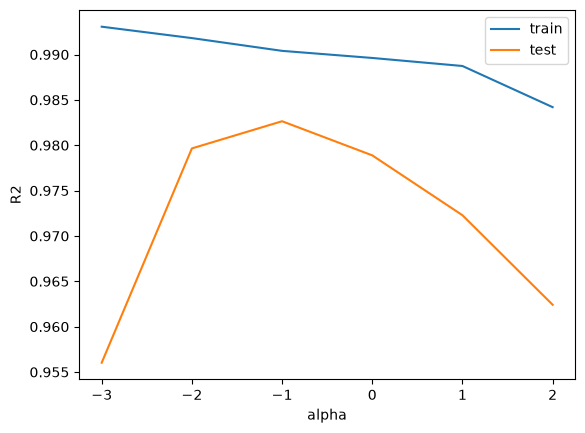

In [ ]:
#Ridge - alpha에 따른 R2 그래프
# 위에서 쌓은 train_scores, test_scores를 이용하여 그래프 그리기
import matplotlib.pyplot as plt

plt.plot(np.log10(alpha_list), train_scores, label='train') #10배롤 말고 log10으로 보기 편하게하기
plt.plot(np.log10(alpha_list), test_scores, label='test')
plt.xlabel('alpha')
plt.ylabel('R2')
plt.legend()
plt.show()

# 결과로 볼 수 있는 것
# alpha가 0.1일 때, train과 test의 R2가 가장 높다. 따라서 alpha=0.1이 가장 적절한 규제강도라고 판단할 수 있다.

In [26]:
#실험을 통해 찾은 최적의 알파값(0.1)로 릿지회귀 재학습
ridge = Ridge(alpha=0.1)
ridge.fit(train_scaled, train_target)
print(ridge.score(train_scaled, train_target), ridge.score(test_scaled, test_target))

0.990404845594141 0.9826465162736733


In [27]:
#랏쏘 회귀로 과대적합 규제하기
from sklearn.linear_model import Lasso
lasso = Lasso()
lasso.fit(train_scaled, train_target)
print(lasso.score(train_scaled, train_target), lasso.score(test_scaled, test_target))

0.9898014198970121 0.9798798667260247


In [28]:
# Lasso - 최적의 alpha를 찾기위해 alpha에 대한 R2 확인

train_scores = []
test_scores = []
alpha_list = [0.001, 0.01, 0.1, 1, 10, 100]

for a in alpha_list:
  lasso = Lasso(alpha = a, max_iter=10000)
  lasso.fit(train_scaled, train_target)
  train_scores.append(lasso.score(train_scaled, train_target))
  test_scores.append(lasso.score(test_scaled, test_target))

/home/dldmswl/class_python/class_python/.venv/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.872149e+04, tolerance: 5.183e+02
  model = cd_fast.enet_coordinate_descent(
/home/dldmswl/class_python/class_python/.venv/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.300442e+04, tolerance: 5.183e+02
  model = cd_fast.enet_coordinate_descent(


In [29]:
# ConvergenceWarning 해결을 위해 max_iter와 tol을 조절한 Lasso 최적 alpha 탐색
from sklearn.linear_model import Lasso
import numpy as np

train_scores = []
test_scores = []
alpha_list = [0.001, 0.01, 0.1, 1, 10, 100]

for a in alpha_list:
  # max_iter를 100,000으로 늘리고, 필요 시 허용오차(tol)를 조금 늘려 수렴을 돕습니다.
  lasso_temp = Lasso(alpha=a, max_iter=100000, tol=0.01)
  lasso_temp.fit(train_scaled, train_target)

  train_scores.append(lasso_temp.score(train_scaled, train_target))
  test_scores.append(lasso_temp.score(test_scaled, test_target))

In [30]:
print(lasso.max_iter)

10000


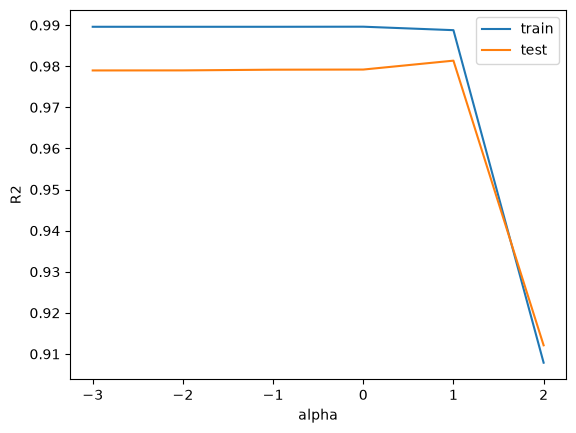

In [ ]:
#Lasso - alpha에 따른 R2 그래프
import matplotlib.pyplot as plt

plt.plot(np.log10(alpha_list), train_scores, label='train')
plt.plot(np.log10(alpha_list), test_scores, label='test')
plt.xlabel('alpha')
plt.ylabel('R2')
plt.legend()
plt.show()

# 결과로 볼 수 있는 것
# alpha가 10일 때, train과 test의 R2가 가장 높다.

In [33]:
# 실험을 통해 찾은 최적의 알파값(1)로 Lasso 회귀 재학습
lasso = Lasso(alpha=10)
lasso.fit(train_scaled, train_target)
print(lasso.score(train_scaled, train_target), lasso.score(test_scaled, test_target))

0.988820885788649 0.9823020708550178


In [34]:
#라쏘모델에서 계수가 0인 항의 개수는?
print(np.sum(lasso.coef_ == 0))
print(lasso.coef_)

40
[ 0.          0.          0.         13.11036343 55.12266859 41.48994624
  0.          0.         13.9830843   0.         43.4392343   4.64928255
 48.51500022  6.26668787 11.80207049  0.          0.         13.35211297
 22.11736679  0.          0.          0.          0.          0.
  0.         19.18672642  0.          0.          0.         15.53954944
  0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.         18.55402184  0.          0.          0.
  0.         14.99032734  0.          0.          0.          0.
  0.        ]


릿지와 라쏘의 차이
릿지는 특성의 제곱을 이용하고
라쏜는 절대값을 취해서 사용한다
그래서 릿지를 더 많이 사용한다
위의 코드응 계수가 0인 것을 찍는다 -> 얘는 학습에 도움을 안 준다 의미 있는 항찾을 수 있다.
릿지와 라쏘는 규제 정도를 설정 하는 것이 중요하다